# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** *(The main goal of this activity is to develop a machine learning model that can classify breast cancer tumors as either malignant or benign using the Wisconsin Diagnostic Breast Cancer dataset. This dataset contains different measurements of cell nuclei that can help identify whether a tumor is cancerous or not. By using these measurements, we can train a model to recognize patterns and make predictions. It is important to choose a reliable model because incorrect predictions can affect a patient's health. In particular, classifying a malignant tumor as benign can be dangerous because it may delay proper medical treatment.)*

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC


from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [2]:
# TODO: load the dataset and copy its DataFrame into df
data = load_breast_cancer(as_frame=True)

df = data.frame.copy()

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names),
      "-> 0 = malignant, 1 = benign")


Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [3]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
print("Dataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes.value_counts())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape:
(569, 31)

Data Types:
float64    30
int64       1
Name: count, dtype: int64

First 5 Rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [4]:
# TODO: class counts and percentages
class_counts = df["target"].value_counts().sort_index()

class_percentages = (
    df["target"].value_counts(normalize=True).sort_index() * 100
)

print("Class Counts:")
print(class_counts.rename(index={
    0: "Malignant",
    1: "Benign"
}))

print("\nClass Percentages:")
print(class_percentages.rename(index={
    0: "Malignant",
    1: "Benign"
}))

Class Counts:
target
Malignant    212
Benign       357
Name: count, dtype: int64

Class Percentages:
target
Malignant    37.258348
Benign       62.741652
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [5]:
# TODO: describe().T, then the 10 largest skewness values
print("Summary Statistics:")
display(df.drop(columns="target").describe().T)

skewness = df.drop(columns="target").skew()

print("\n10 Most Skewed Features:")
display(skewness.abs().sort_values(ascending=False).head(10))

Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



10 Most Skewed Features:


,0
area error,5.447186
concavity error,5.110463
fractal dimension error,3.923969
perimeter error,3.443615
radius error,3.088612
smoothness error,2.314450
symmetry error,2.195133
compactness error,1.902221
worst area,1.859373
worst fractal dimension,1.662579


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [6]:
# TODO: correlation with target, sorted
correlations = (
    df.drop(columns="target")
    .corrwith(df["target"])
    .sort_values()
)

print("5 Most Negative Correlations:")
display(correlations.head(5))

print("\n5 Most Positive Correlations:")
display(correlations.tail(5))

5 Most Negative Correlations:


,0
worst concave points,-0.793566
worst perimeter,-0.782914
mean concave points,-0.776614
worst radius,-0.776454
mean perimeter,-0.742636



5 Most Positive Correlations:


,0
fractal dimension error,-0.077972
symmetry error,0.006522
texture error,0.008303
mean fractal dimension,0.012838
smoothness error,0.067016


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** *(Based on the initial analysis, the dataset contains different features that describe the characteristics of breast cancer tumors. These features have different values and distributions, which can help us understand the differences between malignant and benign tumors. Some features may have higher values or greater variation than others. Examining the descriptive statistics helps us understand the overall condition of the data before applying machine learning algorithms. This step is important because it allows us to identify possible patterns, unusual values, and relationships between the features.)*

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

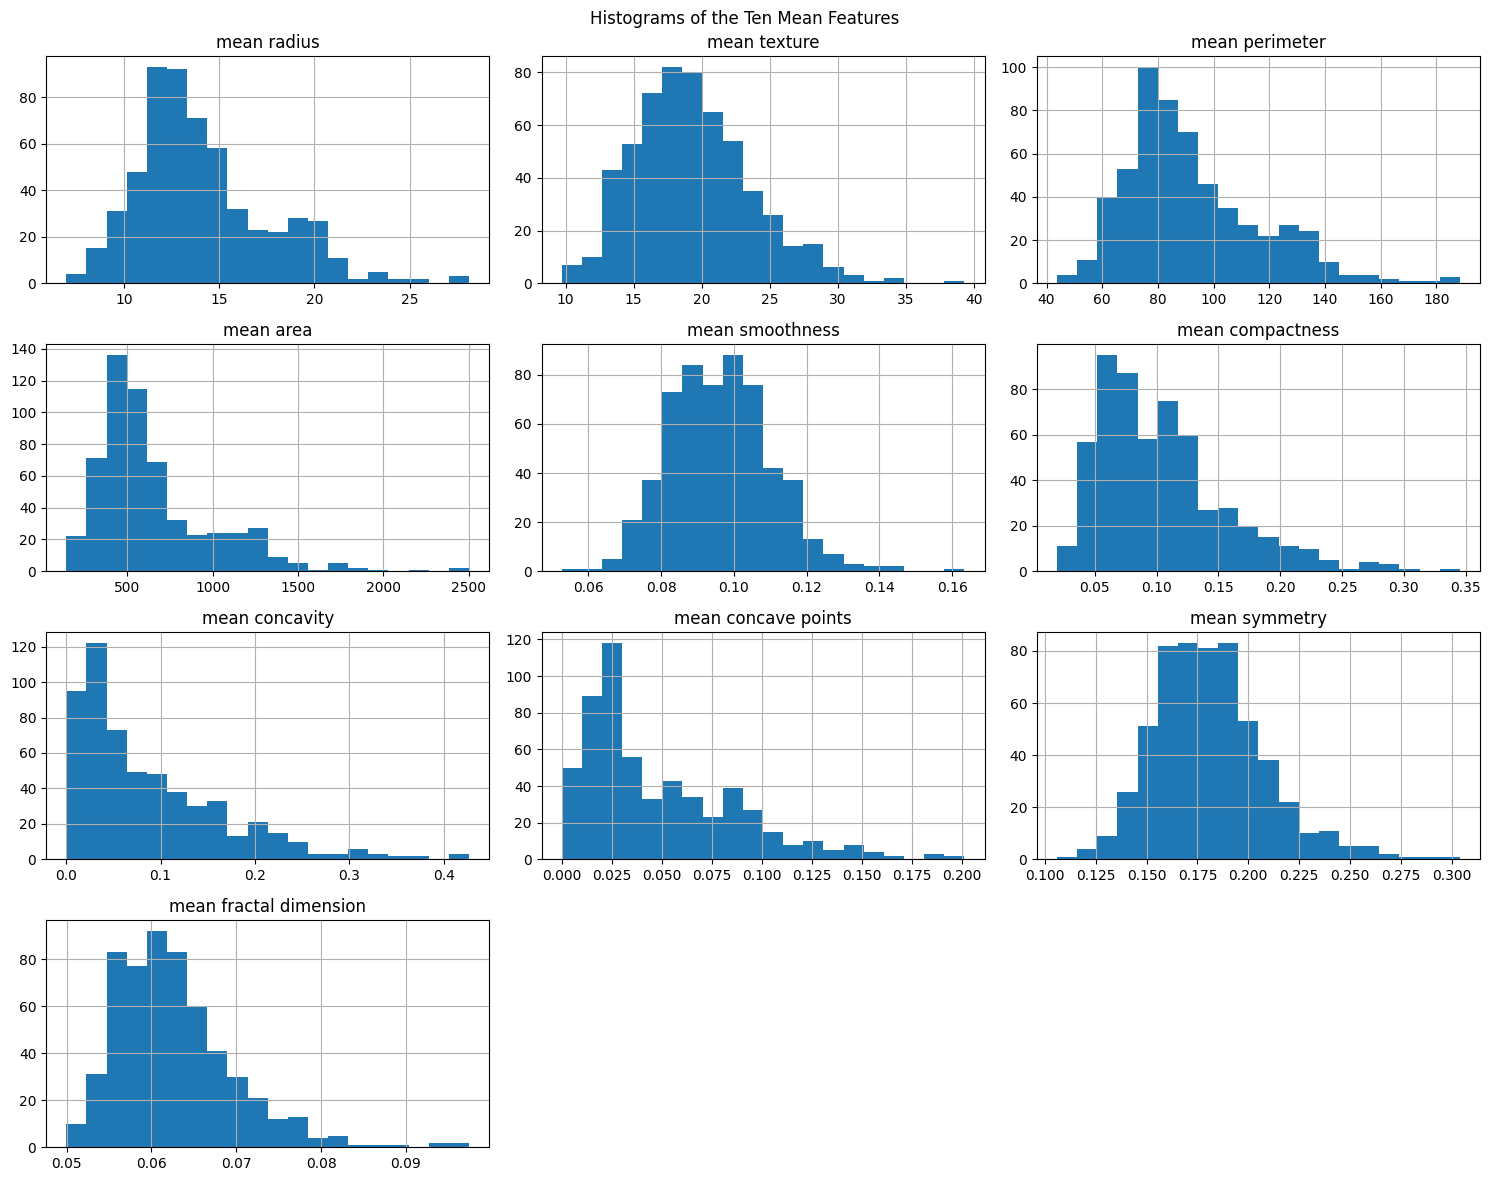

In [7]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
mean_features = df.filter(like="mean").drop(columns="target",
                                             errors="ignore")

mean_features.hist(figsize=(15, 12), bins=20)

plt.suptitle("Histograms of the Ten Mean Features")
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

<Figure size 1000x800 with 0 Axes>

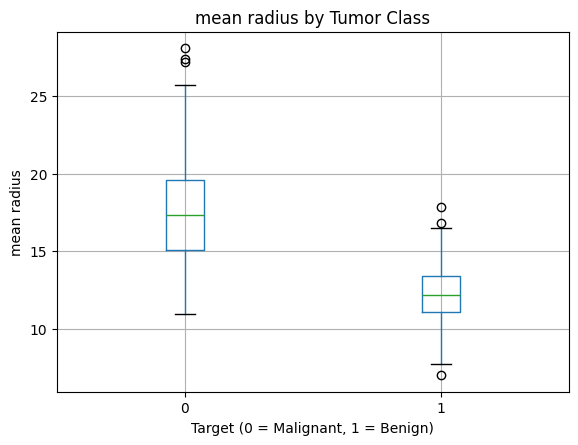

<Figure size 1000x800 with 0 Axes>

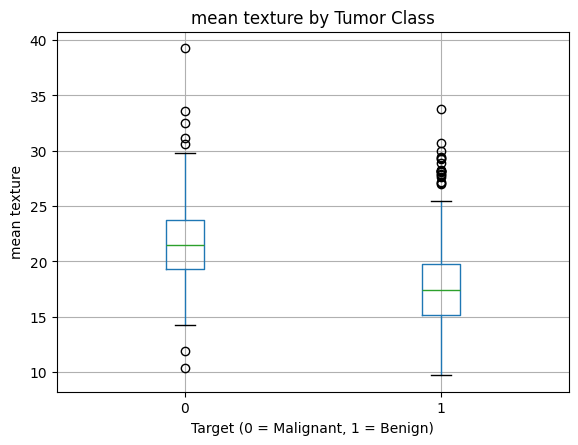

<Figure size 1000x800 with 0 Axes>

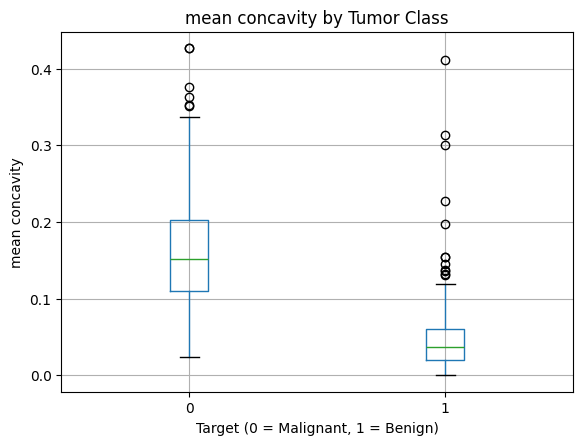

<Figure size 1000x800 with 0 Axes>

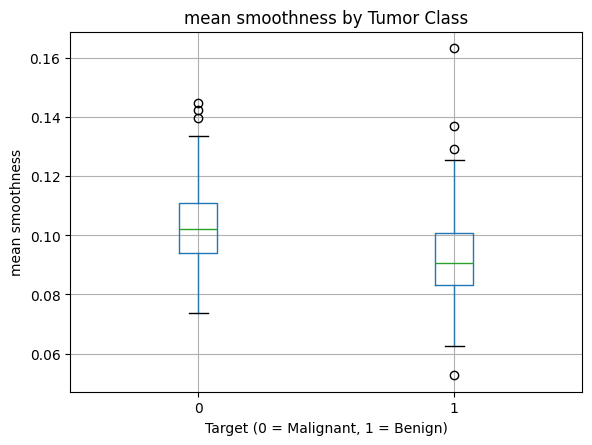

In [9]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target


for feature in features:
    plt.figure(figsize=(10, 8))

    df.boxplot(
        column=feature,
        by="target"
    )

    plt.title(f"{feature} by Tumor Class")
    plt.suptitle("")
    plt.xlabel("Target (0 = Malignant, 1 = Benign)")
    plt.ylabel(feature)

    plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

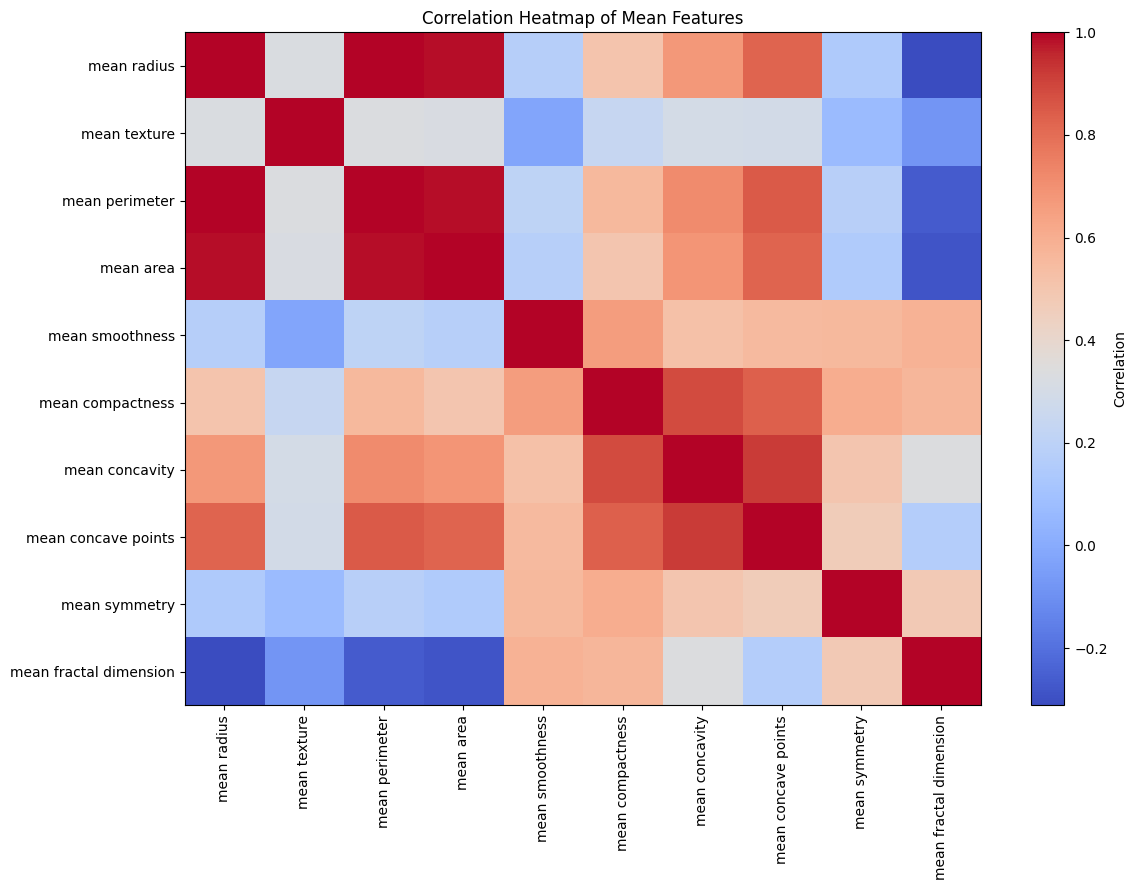

In [10]:
# TODO: correlation matrix of the "mean" features drawn with imshow
mean_features = df.filter(like="mean").drop(
    columns="target",
    errors="ignore"
)

corr_matrix = mean_features.corr()

plt.figure(figsize=(12, 9))

plt.imshow(corr_matrix, cmap="coolwarm", aspect="auto")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("Correlation Heatmap of Mean Features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

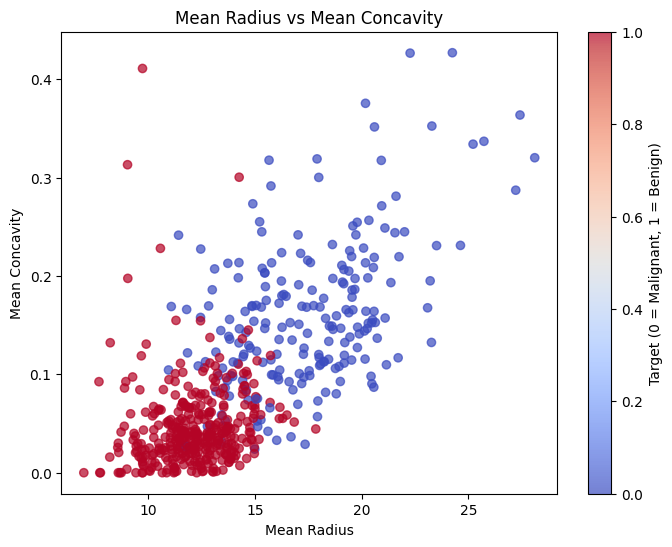

In [11]:
# TODO: coloured scatter plot with axis labels and a colourbar
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df["mean radius"],
    df["mean concavity"],
    c=df["target"],
    cmap="coolwarm",
    alpha=0.7
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs Mean Concavity")

plt.colorbar(
    scatter,
    label="Target (0 = Malignant, 1 = Benign)"
)

plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** *(The visualizations help us understand the dataset more clearly by showing the distribution and relationships of the features. Histograms show how the values are spread, while boxplots help identify possible outliers. The correlation heatmap shows which features have strong relationships with one another. These visualizations are useful because they make it easier to recognize patterns and differences between malignant and benign tumors. Through this process, we can better understand the data and prepare it for model training.)*

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [12]:
# TODO: total missing values and duplicated rows
print("Total Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


X = df.drop(columns="target")
y = df["target"]

Total Missing Values:
0

Duplicate Rows:
0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [13]:
# TODO: IQR outlier count per feature
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = (
    ((X < lower_bound) | (X > upper_bound))
    .sum()
    .sort_values(ascending=False)
)

print("10 Features with the Most Outliers:")
display(outlier_counts.head(10))

10 Features with the Most Outliers:


,0
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
fractal dimension error,28
compactness error,28
symmetry error,27
mean area,25
worst fractal dimension,24


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** *(No, I would not immediately delete the outlying rows because they may contain important information about the characteristics of breast cancer tumors. Some outliers could represent actual differences between malignant and benign cases rather than errors in the data. Removing them might result in losing useful information and could affect the model's performance. I would first check whether the outliers are caused by incorrect or unusual measurements. If they are valid observations, I would keep them in the dataset.)*

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [14]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
corr_matrix = X.corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.95)
]

print("Features with Correlation Above 0.95:")
print(high_corr_features)

Features with Correlation Above 0.95:
['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [15]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
selector = SelectKBest(score_func=f_classif, k=10)

selector.fit(X, y)

kbest_scores = pd.Series(
    selector.scores_,
    index=X.columns
).sort_values(ascending=False)

print("Top 10 Features Using SelectKBest:")
display(kbest_scores.head(10))

Top 10 Features Using SelectKBest:


,0
worst concave points,964.385393
worst perimeter,897.944219
mean concave points,861.676020
worst radius,860.781707
mean perimeter,697.235272
worst area,661.600206
mean radius,646.981021
mean area,573.060747
mean concavity,533.793126
worst concavity,436.691939


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [16]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

log_model = LogisticRegression(max_iter=10000)

rfe = RFE(
    estimator=log_model,
    n_features_to_select=10
)

rfe.fit(X_scaled, y)

rfe_features = X.columns[rfe.support_].tolist()

print("Selected RFE Features:")
print(rfe_features)

Selected RFE Features:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

Top 10 Features Using Extra Trees:


,0
worst concave points,0.111981
worst radius,0.086108
worst area,0.083990
mean concave points,0.075045
worst perimeter,0.074022
mean perimeter,0.061303
mean radius,0.058711
mean concavity,0.055757
mean area,0.051197
worst concavity,0.047384


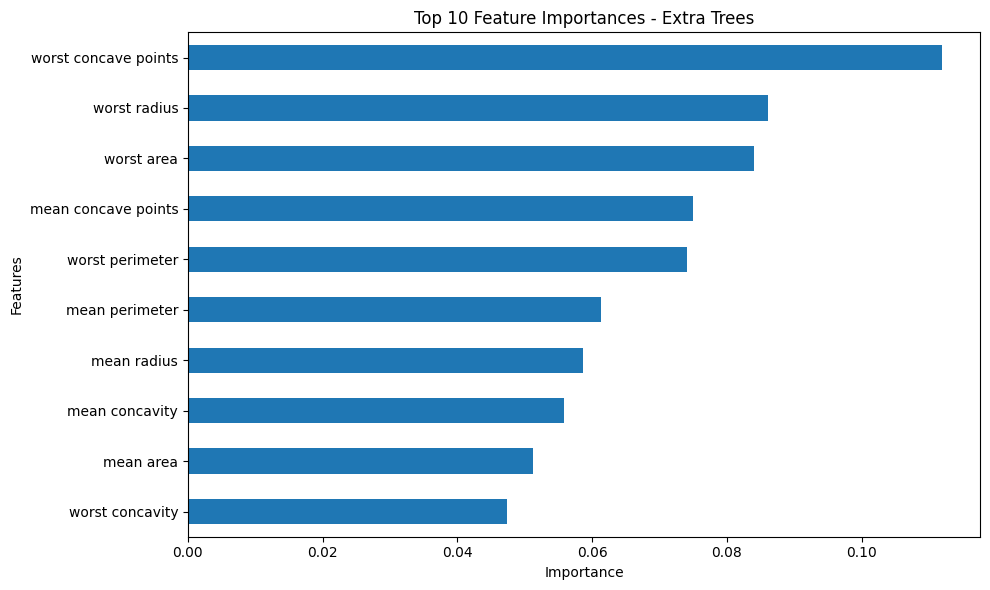

In [17]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
extra_trees = ExtraTreesClassifier(
    n_estimators=200,
    random_state=7
)

extra_trees.fit(X, y)

imp = pd.Series(
    extra_trees.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top 10 Features Using Extra Trees:")
display(imp.head(10))

plt.figure(figsize=(10, 6))

imp.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Feature Importances - Extra Trees")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [18]:
# TODO: vote across the three methods
kbest_features = kbest_scores.head(10).index.tolist()

extra_features = imp.head(10).index.tolist()

feature_votes = {}

for feature in X.columns:
    votes = (
        feature in kbest_features
    ) + (
        feature in rfe_features
    ) + (
        feature in extra_features
    )

    feature_votes[feature] = votes

selected = [
    feature
    for feature, votes in feature_votes.items()
    if votes >= 2
]

print("Selected Features:")
print(selected)

print("\nNumber of Selected Features:")
print(len(selected))

Selected Features:
['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']

Number of Selected Features:
10


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [20]:
# TODO: train_test_split with stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=7,
    stratify=y
)


print("Training Set", X_train.shape, "Testing Set", X_test.shape)

Training Set (455, 30) Testing Set (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [21]:
# TODO: fit both scalers on X_train and print the verifying statistics
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X_train_standard = standard_scaler.fit_transform(X_train)

X_train_minmax = minmax_scaler.fit_transform(X_train)

standard_df = pd.DataFrame(
    X_train_standard,
    columns=X_train.columns
)

minmax_df = pd.DataFrame(
    X_train_minmax,
    columns=X_train.columns
)

print("StandardScaler - Mean and Standard Deviation:")
display(
    pd.DataFrame({
        "Mean": standard_df.iloc[:, :4].mean(),
        "Standard Deviation": standard_df.iloc[:, :4].std()
    })
)

print("\nMinMaxScaler - Minimum and Maximum:")
display(
    pd.DataFrame({
        "Minimum": minmax_df.iloc[:, :4].min(),
        "Maximum": minmax_df.iloc[:, :4].max()
    })
)

StandardScaler - Mean and Standard Deviation:


,Mean,Standard Deviation
mean radius,9.369794e-17,1.001101
mean texture,-3.747918e-16,1.001101
mean perimeter,-5.797560e-16,1.001101
mean area,-3.279428e-16,1.001101



MinMaxScaler - Minimum and Maximum:


,Minimum,Maximum
mean radius,0.0,1.0
mean texture,0.0,1.0
mean perimeter,0.0,1.0
mean area,0.0,1.0


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [22]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
pca = PCA()

pca.fit(X_train_standard)

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

components_95 = np.argmax(
    cumulative_variance >= 0.95
) + 1

print(
    "Number of Principal Components needed for 95% variance:",
    components_95
)

Number of Principal Components needed for 95% variance: 10


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [29]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM

models = {
    "LR": LogisticRegression(max_iter=10000),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC()
}

def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [30]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
raw_results = spot_check(
    models,
    X_train,
    scale=False
)

scaled_results = spot_check(
    models,
    X_train,
    scale=True
)

summary = pd.DataFrame({
    "raw": {
        name: scores.mean()
        for name, scores in raw_results.items()
    },
    "scaled": {
        name: scores.mean()
        for name, scores in scaled_results.items()
    }
})

print("Mean Cross-Validation Accuracy:")
display(summary)

Mean Cross-Validation Accuracy:


,raw,scaled
LR,0.953768,0.982319
LDA,0.947246,0.947246
KNN,0.922947,0.964928
CART,0.927633,0.927633
NB,0.934058,0.932029
SVM,0.898696,0.975797


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** *(The models that benefit most from feature scaling are K-Nearest Neighbors (KNN), Support Vector Machine (SVM), Logistic Regression, and Linear Discriminant Analysis (LDA). These models are affected by the scale of the features, so variables with larger values may have more influence on the results. Scaling helps put the features on a similar range, allowing the models to learn and make predictions more fairly. KNN and SVM especially benefit from scaling because they rely on distances or calculations that are sensitive to differences in feature values.)*

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [31]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
selected_results = spot_check(
    models,
    X_train[selected],
    scale=True
)

selected_summary = pd.DataFrame({
    "All Features": {
        name: scores.mean()
        for name, scores in scaled_results.items()
    },
    "Selected Features": {
        name: scores.mean()
        for name, scores in selected_results.items()
    }
})

print("Comparison of All Features and Selected Features:")
display(selected_summary)

Comparison of All Features and Selected Features:


,All Features,Selected Features
LR,0.982319,0.960435
LDA,0.947246,0.942995
KNN,0.964928,0.942802
CART,0.927633,0.921014
NB,0.932029,0.951691
SVM,0.975797,0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

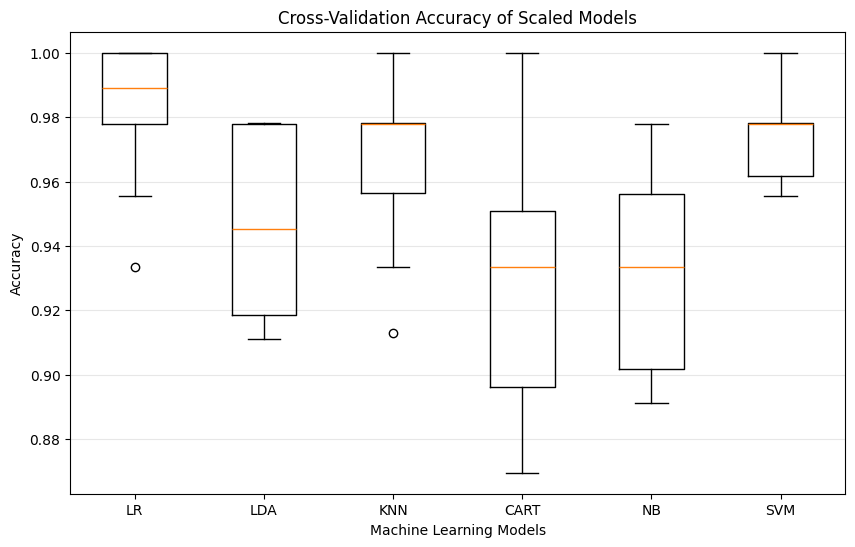

In [32]:
# TODO: box plot of the 10 fold scores per model
plt.figure(figsize=(10, 6))

plt.boxplot(
    [scaled_results[name] for name in scaled_results],
    labels=list(scaled_results.keys())
)

plt.title("Cross-Validation Accuracy of Scaled Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")

plt.grid(axis="y", alpha=0.3)
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [33]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
best_model_name = summary["scaled"].idxmax()

best_model = models[best_model_name]

best_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", best_model)
])

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "malignant_recall": make_scorer(
        recall_score,
        pos_label=0
    )
}

metrics_results = cross_validate(
    best_pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring=scoring
)

print("Best Scaled Model:", best_model_name)

print("\nAverage Cross-Validation Metrics:")

for metric in scoring:
    scores = metrics_results["test_" + metric]

    print(
        metric,
        ":",
        round(scores.mean(), 4)
    )

Best Scaled Model: LR

Average Cross-Validation Metrics:
accuracy : 0.9823
roc_auc : 0.9922
malignant_recall : 0.9647


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [34]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
svm_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC())
])

svm_parameters = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_parameters,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("Best SVM Parameters:")
print(svm_grid.best_params_)

print("\nBest SVM Accuracy:")
print(svm_grid.best_score_)

Best SVM Parameters:
{'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}

Best SVM Accuracy:
0.9801932367149758


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [35]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
knn_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

knn_parameters = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_parameters,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("Best KNN Parameters:")
print(knn_grid.best_params_)

print("\nBest KNN Accuracy:")
print(knn_grid.best_score_)

Best KNN Parameters:
{'model__n_neighbors': 3, 'model__weights': 'uniform'}

Best KNN Accuracy:
0.9692753623188406


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [36]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
ensembles = {
    "RF": RandomForestClassifier(
        n_estimators=200,
        random_state=seed
    ),

    "ET": ExtraTreesClassifier(
        n_estimators=200,
        random_state=seed
    ),

    "GB": GradientBoostingClassifier(
        random_state=seed
    ),

    "AB": AdaBoostClassifier(
        random_state=seed
    )
}

ensemble_results = spot_check(
    ensembles,
    X_train,
    scale=False
)

voting_model = VotingClassifier(
    estimators=[
        ("svm", svm_grid.best_estimator_),
        ("knn", knn_grid.best_estimator_),
        ("rf", ensembles["RF"])
    ],
    voting="hard"
)

voting_pipeline = Pipeline([
    ("model", voting_model)
])

voting_scores = cross_val_score(
    voting_pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring="accuracy"
)

print("Ensemble Model Results:")

for name, scores in ensemble_results.items():
    print(name, ":", scores.mean())

print("Voting Ensemble:", voting_scores.mean())

Ensemble Model Results:
RF : 0.9647826086956522
ET : 0.971400966183575
GB : 0.9669565217391305
AB : 0.96256038647343
Voting Ensemble: 0.9780676328502416


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [37]:
# TODO: leaderboard Series
leaderboard_scores = {
    "Tuned SVM": svm_grid.best_score_,
    "Tuned KNN": knn_grid.best_score_
}

for name, scores in ensemble_results.items():
    leaderboard_scores[name] = scores.mean()

leaderboard_scores["Voting Ensemble"] = voting_scores.mean()

leaderboard = pd.Series(
    leaderboard_scores
).sort_values(ascending=False)

print("Model Leaderboard:")
display(leaderboard)

Model Leaderboard:


,0
Tuned SVM,0.980193
Voting Ensemble,0.978068
ET,0.971401
Tuned KNN,0.969275
GB,0.966957
RF,0.964783
AB,0.962560


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Winning Model: Tuned SVM

Test Accuracy:
0.9649122807017544

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114


Confusion Matrix:


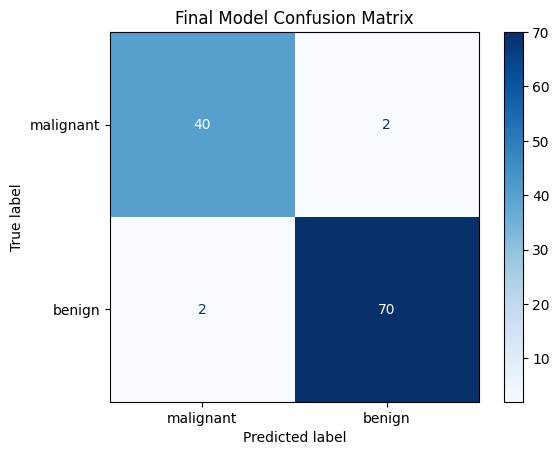

In [38]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix

winner_name = leaderboard.index[0]

print("Winning Model:", winner_name)

if winner_name == "Tuned SVM":
    final_model = svm_grid.best_estimator_

elif winner_name == "Tuned KNN":
    final_model = knn_grid.best_estimator_

elif winner_name == "Voting Ensemble":
    final_model = voting_pipeline

else:
    final_model = Pipeline([
        ("model", ensembles[winner_name])
    ])

final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)

print("\nTest Accuracy:")
print(accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    )
)

print("\nConfusion Matrix:")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=data.target_names,
    cmap="Blues"
)

plt.title("Final Model Confusion Matrix")
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [39]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
import joblib

joblib.dump(final_model, "breast_cancer_model.pkl")

loaded_model = joblib.load("breast_cancer_model.pkl")

loaded_predictions = loaded_model.predict(X_test)

print("Original Predictions:")
print(y_pred[:5])

print("\nLoaded Model Predictions:")
print(loaded_predictions[:5])

print(
    "\nPredictions Match:",
    np.array_equal(y_pred, loaded_predictions)
)

Original Predictions:
[0 0 1 0 1]

Loaded Model Predictions:
[0 0 1 0 1]

Predictions Match: True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`. *(Feature selection using the whole dataset can cause data leakage because information from the testing folds is already used when selecting the most important features. This can make the cross-validation scores look higher than the actual performance of the model. To prevent this, I would use a Pipeline so that feature selection and model training are performed separately within each training fold. This ensures that the model does not use information from the validation data during training and gives a more reliable evaluation.)*
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient? *(I would report recall for the malignant class to a clinician because it measures how many actual malignant cases are correctly identified by the model. This is important because failing to detect a malignant tumor could delay a patient's treatment. Accuracy alone is insufficient because it only measures the overall percentage of correct predictions and may hide cases where the model fails to identify cancer. I would also include precision, F1-score, and ROC-AUC to provide a more complete evaluation.)*
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.) *(If two models differ by only 0.3% in cross-validation accuracy, I would not automatically choose the model with the slightly higher score. I would compare their performance across all folds to see which model has more consistent results and lower variation. I would also consider interpretability, training time, and complexity. If both models perform almost equally, I would prefer the simpler and more understandable model because it is easier to explain and maintain.)*
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset? *(If the dataset were much smaller, I would be more careful when interpreting the results because the model might not have enough examples to learn reliable patterns. I would use cross-validation to make better use of the available data and avoid relying on a single train-test split. If the dataset were more imbalanced, I would focus more on metrics such as recall, precision, and F1-score instead of accuracy alone. I would also consider using class weights or resampling techniques to help the model recognize the minority class.)*
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change. *(If I repeated this workbook using another dataset, such as one loaded from an ARFF file, I would follow most of the same machine learning steps. However, I would first need to understand the new dataset, identify its target variable, and check its features and data types. Some preprocessing steps might change depending on whether the dataset contains missing values, categorical variables, or imbalanced classes. I would also adjust the feature selection and model evaluation based on the new dataset. This would help me understand how the same machine learning process can be applied to different classification problems.)*

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.